In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.metrics import root_mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
import warnings 
warnings.filterwarnings('ignore')
import os 
os.chdir("E:/Machine_Learning/Datasets/")

In [2]:
df = pd.read_csv('FMAC-HPI_24420.csv')
df.head()

,Date,NSA Value,SA Value
0,31-01-1975,24.739893,24.687815
1,28-02-1975,25.266825,25.200482
2,31-03-1975,25.765667,25.633002
3,30-04-1975,26.212724,26.009987
4,31-05-1975,26.628081,26.350592


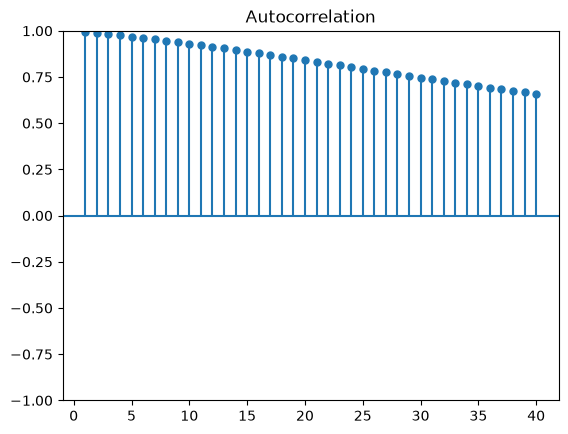

In [3]:
plot_acf(df['NSA Value'],lags=40,alpha=None,zero=False)
plt.show()

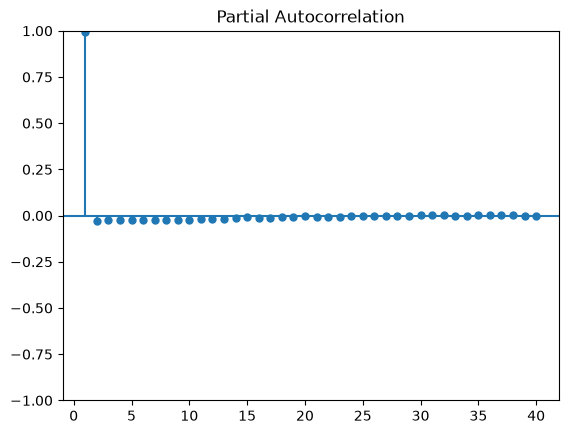

In [4]:
plot_pacf(df['NSA Value'],lags=40,alpha=None,zero=False)
plt.show()

In [5]:
y = df['NSA Value']
y_train = y[:-12]
y_test = y[-12:]

In [6]:
model = ARIMA(y_train,order=(2,1,1))
model_fit = model.fit()
print('Coefficient: %s' % model_fit.params)
predictions = model_fit.predict(start = len(y_train),end = len(y_train)+len(y_test)-1)
error = root_mean_squared_error(y_test,predictions)
print('Test RMSE : %.3f' % error)

Coefficient: ar.L1     1.473144
ar.L2    -0.589775
ma.L1     0.999739
sigma2    0.035254
dtype: float64
Test RMSE : 3.184


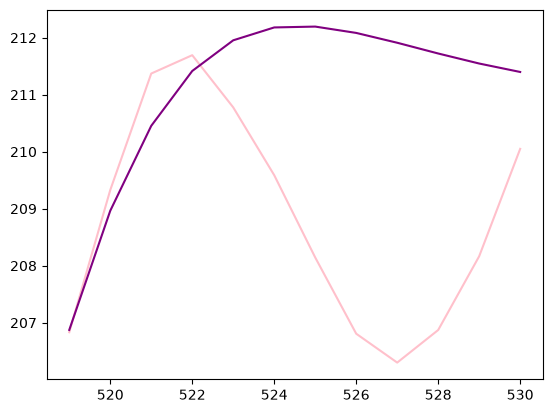

In [7]:
y_test.plot(color = 'pink')
predictions.plot(color = 'purple')
plt.show()

# Auto-ARIMA

In [8]:
from pmdarima.arima import auto_arima

In [9]:
model = auto_arima(y_train,trace=True,error_action='ignore',suppress_warnings=True)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-258.744, Time=0.85 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=1625.721, Time=0.03 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=545.901, Time=0.13 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.31 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=1668.139, Time=0.02 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=-211.845, Time=0.76 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.76 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=1.50 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=2.59 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.64 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=1.62 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.51 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=2.07 sec
 ARIMA(2,1,2)(0,0,0)[0]             : AIC=-254.857, Time=0.66 sec

Best model:  ARIMA(2,1,2)(0,0,0)[0] intercept
Total fit time: 12.500 seco

In [10]:
model.bse

<bound method ARIMA.bse of ARIMA(order=(2, 1, 2), scoring_args={}, suppress_warnings=True)>

In [11]:
forecast = model.predict(n_periods=len(y_train))
forecast = pd.DataFrame(forecast,index=y_test.index,columns=['Prediction'])
rms = root_mean_squared_error(y_test,forecast)
print('Test RMSE : %.3f' % rms)

Test RMSE : 4.213
